In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [8]:

import os

DRIVE_ROOT = "/content/drive/MyDrive"

required_files = [
    "train_candidates.csv",
    "train_coverage.csv",
    "student_test_candidates.csv",
    "student_test_coverage.csv",
    "README.md",
    "fold_assignments.json"
]

file_paths = {}

for root, dirs, files in os.walk(DRIVE_ROOT):
    for filename in required_files:
        if filename in files:
            file_paths[filename] = os.path.join(root, filename)

print("PREPROCESSED DATA FILES")
print("-" * 50)

for filename in required_files:
    print(filename, ":", file_paths.get(filename, "NOT FOUND"))


PREPROCESSED DATA FILES
--------------------------------------------------
train_candidates.csv : /content/drive/MyDrive/Data Set/train_candidates.csv
train_coverage.csv : /content/drive/MyDrive/Data Set/train_coverage.csv
student_test_candidates.csv : /content/drive/MyDrive/Data Set/student_test_candidates.csv
student_test_coverage.csv : /content/drive/MyDrive/Data Set/student_test_coverage.csv
README.md : /content/drive/MyDrive/Data Set/README.md
fold_assignments.json : /content/drive/MyDrive/Data Set/fold_assignments.json


Cell 3 — Load the preprocessed datasets

In [9]:

import pandas as pd
import json

train_df = pd.read_csv(file_paths["train_candidates.csv"])
train_coverage_df = pd.read_csv(file_paths["train_coverage.csv"])

student_test_df = pd.read_csv(
    file_paths["student_test_candidates.csv"]
)

student_coverage_df = pd.read_csv(
    file_paths["student_test_coverage.csv"]
)

print("TRAIN CANDIDATES:", train_df.shape)
print("TRAIN COVERAGE:", train_coverage_df.shape)

print("STUDENT TEST CANDIDATES:", student_test_df.shape)
print("STUDENT TEST COVERAGE:", student_coverage_df.shape)


TRAIN CANDIDATES: (1147959, 8)
TRAIN COVERAGE: (208417, 7)
STUDENT TEST CANDIDATES: (108759, 8)
STUDENT TEST COVERAGE: (19160, 7)


Cell 6 — Inspect training dataset

In [10]:

DATA_DIR = "/content/drive/MyDrive/Data Set"

print("TRAINING DATA INFORMATION")
print("=" * 60)

print("Shape:", train_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

print("\nFirst 10 rows:")
display(train_df.head(10))

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nUnique values per column:")
print(train_df.nunique())


TRAINING DATA INFORMATION
Shape: (1147959, 8)

Columns:
['trip_id', 'observation_id', 'candidate_id', 'label', 'distance_to_segment_m', 'projection_fraction', 'observation_speed_mps', 'heading_difference_rad']

Data types:
trip_id                     int64
observation_id              int64
candidate_id                int64
label                       int64
distance_to_segment_m     float64
projection_fraction       float64
observation_speed_mps     float64
heading_difference_rad    float64
dtype: object

First 10 rows:


,trip_id,observation_id,candidate_id,label,distance_to_segment_m,projection_fraction,observation_speed_mps,heading_difference_rad
0,1,0,64973,1,0.721054,0.109777,0.000000,0.000000
1,1,0,117639,0,15.086314,0.512703,0.000000,0.000000
2,1,0,2641,0,32.200990,1.000000,0.000000,0.000000
3,1,1,64973,1,0.276347,0.258530,43.634296,0.022865
4,1,1,117639,0,16.031254,0.469955,43.634296,3.119945
5,1,2,64973,1,1.835393,0.426569,49.323807,0.042823
6,1,2,117639,0,13.860255,0.421669,49.323807,3.097552
7,1,3,64973,1,6.131564,0.614298,55.219950,0.077877
8,1,3,117639,0,9.497884,0.367728,55.219950,3.062498
9,1,4,64973,1,2.644886,0.759946,43.604720,0.202658



Missing values:
trip_id                   0
observation_id            0
candidate_id              0
label                     0
distance_to_segment_m     0
projection_fraction       0
observation_speed_mps     0
heading_difference_rad    0
dtype: int64

Unique values per column:
trip_id                        80
observation_id              16040
candidate_id                55237
label                           2
distance_to_segment_m      665565
projection_fraction        495771
observation_speed_mps      178586
heading_difference_rad    1138126
dtype: int64


Cell 7 — Inspect labels and trip distribution

In [11]:

print("TRAINING LABEL DISTRIBUTION")
print("=" * 60)

for col in train_df.columns:
    if train_df[col].nunique() <= 10:
        print(f"\n{col}:")
        print(train_df[col].value_counts().head(10))

print("\nStudent testing shape:", student_test_df.shape)


TRAINING LABEL DISTRIBUTION

label:
label
0    968957
1    179002
Name: count, dtype: int64

Student testing shape: (108759, 8)


Cell 8 — Read preprocessing methodology

In [12]:

with open(os.path.join(DATA_DIR, "README.md"), "r") as f:
    print(f.read())


# PathSnap Pre-Processed Dataset

This folder contains the complete, model-neutral pre-processed candidate datasets and cross-validation fold assignments for the PathSnap ML project.

---

## 📁 Files in This Directory

| File Name | Rows | Size | Description |
|---|---|---|---|
| [`train_candidates.csv`](file:///C:/Users/Shibi%20R%20Shetty/ML%20HACKTHON/preprocessed_data/train_candidates.csv) | 1,147,959 | ~96 MB | Candidate rows for training & 5-fold cross-validation across 80 training trips. |
| [`student_test_candidates.csv`](file:///C:/Users/Shibi%20R%20Shetty/ML%20HACKTHON/preprocessed_data/student_test_candidates.csv) | 108,759 | ~9.1 MB | Candidate rows for held-out evaluation across 10 student-test trips. |
| [`train_coverage.csv`](file:///C:/Users/Shibi%20R%20Shetty/ML%20HACKTHON/preprocessed_data/train_coverage.csv) | 208,417 | ~7.4 MB | Observation-level metadata for all 208,417 GPS points in `train` (coverage & miss-rate tracking). |
| [`student_test_coverage.csv`](file:///

Cell 9 — Inspect fold assignments

In [13]:

with open(
    os.path.join(DATA_DIR, "fold_assignments.json"), "r"
) as f:
    fold_assignments = json.load(f)

print("Fold assignment structure:")

if isinstance(fold_assignments, dict):
    print("Keys:", list(fold_assignments.keys()))

print("\nSample:")
print(str(fold_assignments)[:2000])


Fold assignment structure:
Keys: ['n_splits', 'random_state', 'folds']

Sample:
{'n_splits': 5, 'random_state': 42, 'folds': {'0': {'train_trips': ['00000001', '00000002', '00000003', '00000004', '00000005', '00000006', '00000008', '00000010', '00000011', '00000013', '00000014', '00000016', '00000018', '00000019', '00000020', '00000021', '00000022', '00000024', '00000027', '00000028', '00000029', '00000031', '00000032', '00000035', '00000036', '00000037', '00000038', '00000039', '00000042', '00000043', '00000045', '00000046', '00000047', '00000048', '00000050', '00000051', '00000053', '00000054', '00000060', '00000062', '00000063', '00000064', '00000066', '00000068', '00000069', '00000070', '00000071', '00000072', '00000075', '00000078', '00000079', '00000080', '00000082', '00000083', '00000085', '00000086', '00000088', '00000089', '00000090', '00000092', '00000093', '00000096', '00000097', '00000098', '00000099'], 'val_trips': ['00000012', '00000025', '00000026', '00000033', '00000034

# **SVM** implementation

Cell 10 — Define features and target

In [14]:

FEATURE_COLS = [
    "distance_to_segment_m",
    "projection_fraction",
    "observation_speed_mps",
    "heading_difference_rad"
]

TARGET_COL = "label"

X = train_df[FEATURE_COLS]
y = train_df[TARGET_COL]

# Convert trip IDs into the same format as fold_assignments.json
train_df["trip_id"] = train_df["trip_id"].astype(str).str.zfill(8)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

print("\nPositive class percentage:",
      round(y.mean() * 100, 2), "%")

print("\nFeatures selected:")
print(FEATURE_COLS)


Feature shape: (1147959, 4)
Target shape: (1147959,)

Class distribution:
label
0    968957
1    179002
Name: count, dtype: int64

Positive class percentage: 15.59 %

Features selected:
['distance_to_segment_m', 'projection_fraction', 'observation_speed_mps', 'heading_difference_rad']


Cell 11 — Load frozen cross-validation folds

In [15]:

import json

with open(
    os.path.join(DATA_DIR, "fold_assignments.json"), "r"
) as f:
    cv_config = json.load(f)

folds = cv_config["folds"]

print("Number of folds:", len(folds))

for fold_id, assignment in folds.items():
    print(
        f"Fold {fold_id}:",
        len(assignment["train_trips"]), "training trips,",
        len(assignment["val_trips"]), "validation trips"
    )


Number of folds: 5
Fold 0: 65 training trips, 15 validation trips
Fold 1: 63 training trips, 17 validation trips
Fold 2: 64 training trips, 16 validation trips
Fold 3: 64 training trips, 16 validation trips
Fold 4: 64 training trips, 16 validation trips


Define the SVM model

In [16]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

svm_model = Pipeline([
    ("scaler", StandardScaler()),

    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

print("SVM model configured successfully!")
print(svm_model)


SVM model configured successfully!
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LinearSVC(class_weight='balanced', max_iter=5000,
                           random_state=42))])


Perform five-fold cross-validation

In [17]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import time

cv_results = []

for fold_id, assignment in folds.items():

    print(f"\nRunning Fold {fold_id}...")

    train_trip_ids = [
        str(t).zfill(8) for t in assignment["train_trips"]
    ]

    val_trip_ids = [
        str(t).zfill(8) for t in assignment["val_trips"]
    ]

    fold_train = train_df[
        train_df["trip_id"].isin(train_trip_ids)
    ]

    fold_val = train_df[
        train_df["trip_id"].isin(val_trip_ids)
    ]

    X_fold_train = fold_train[FEATURE_COLS]
    y_fold_train = fold_train[TARGET_COL]

    X_fold_val = fold_val[FEATURE_COLS]
    y_fold_val = fold_val[TARGET_COL]

    start = time.time()

    svm_model.fit(X_fold_train, y_fold_train)

    predictions = svm_model.predict(X_fold_val)

    elapsed = time.time() - start

    results = {
        "fold": fold_id,
        "accuracy": accuracy_score(y_fold_val, predictions),
        "precision": precision_score(
            y_fold_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_fold_val, predictions, zero_division=0
        ),
        "macro_f1": f1_score(
            y_fold_val, predictions,
            average="macro",
            zero_division=0
        ),
        "training_time": elapsed
    }

    cv_results.append(results)

    print("Validation samples:", len(fold_val))
    print("Accuracy:", round(results["accuracy"], 4))
    print("Macro F1:", round(results["macro_f1"], 4))
    print("Time:", round(elapsed, 2), "seconds")

cv_results_df = pd.DataFrame(cv_results)

print("\nFINAL CROSS-VALIDATION RESULTS")
display(cv_results_df)



Running Fold 0...
Validation samples: 229202
Accuracy: 0.8082
Macro F1: 0.7236
Time: 2.93 seconds

Running Fold 1...
Validation samples: 231194
Accuracy: 0.7958
Macro F1: 0.694
Time: 2.55 seconds

Running Fold 2...
Validation samples: 228997
Accuracy: 0.8145
Macro F1: 0.7397
Time: 2.06 seconds

Running Fold 3...
Validation samples: 229301
Accuracy: 0.804
Macro F1: 0.7136
Time: 3.26 seconds

Running Fold 4...
Validation samples: 229265
Accuracy: 0.8016
Macro F1: 0.7486
Time: 3.1 seconds

FINAL CROSS-VALIDATION RESULTS


,fold,accuracy,precision,recall,macro_f1,training_time
0,0,0.808160,0.443088,0.801311,0.723563,2.931682
1,1,0.795842,0.368629,0.867355,0.693956,2.546255
2,2,0.814539,0.454290,0.884312,0.739747,2.057930
3,3,0.804017,0.407800,0.856808,0.713560,3.258460
4,4,0.801570,0.496417,0.874238,0.748622,3.101023


Calculate average performance

In [18]:

metrics = [
    "accuracy",
    "precision",
    "recall",
    "macro_f1",
    "training_time"
]

print("AVERAGE FIVE-FOLD PERFORMANCE")
print("=" * 45)

for metric in metrics:
    print(
        f"{metric}: "
        f"{cv_results_df[metric].mean():.4f} "
        f"+/- {cv_results_df[metric].std():.4f}"
    )


AVERAGE FIVE-FOLD PERFORMANCE
accuracy: 0.8048 +/- 0.0070
precision: 0.4340 +/- 0.0483
recall: 0.8568 +/- 0.0326
macro_f1: 0.7239 +/- 0.0216
training_time: 2.7791 +/- 0.4824


Train final SVM using all 80 training trips

In [19]:

start = time.time()

svm_model.fit(
    train_df[FEATURE_COLS],
    train_df[TARGET_COL]
)

final_training_time = time.time() - start

print("Final SVM training completed!")
print("Training samples:", len(train_df))
print("Training time:", round(final_training_time, 2), "seconds")


Final SVM training completed!
Training samples: 1147959
Training time: 1.69 seconds


Evaluate on student-testing data

In [21]:

from sklearn.metrics import classification_report

print("CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Negative", "Positive"],
    zero_division=0
))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.97      0.80      0.88     92335
    Positive       0.44      0.87      0.58     16424

    accuracy                           0.81    108759
   macro avg       0.70      0.84      0.73    108759
weighted avg       0.89      0.81      0.83    108759



In [24]:
MODEL_DIR = DATA_DIR

svm_test_results = pd.DataFrame([{
    "Model": "Linear SVM",
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions),
    "Recall": recall_score(y_test, test_predictions),
    "Macro_F1": f1_score(
        y_test, test_predictions, average="macro"
    ),
    "Inference_Time": inference_time
}])

display(svm_test_results)

svm_test_results.to_csv(
    os.path.join(MODEL_DIR, "svm_student_test_results.csv"),
    index=False
)

print("Results saved successfully!")

,Model,Accuracy,Precision,Recall,Macro_F1,Inference_Time
0,Linear SVM,0.81094,0.436747,0.869825,0.729699,0.006334


Results saved successfully!


## **RBF SVM**

Import and configure RBF SVM

In [25]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import time
import joblib
import os

MODEL_DIR = "/content/pathsnap_models"
os.makedirs(MODEL_DIR, exist_ok=True)

RBF_TRAIN_SIZE = 15000

rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        cache_size=1000
    ))
])

print("RBF SVM configured successfully!")
print(rbf_svm)


RBF SVM configured successfully!
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', SVC(cache_size=1000, class_weight='balanced'))])


Five-fold RBF SVM cross-validation

In [26]:

rbf_cv_results = []

for fold_id, assignment in folds.items():

    print(f"\n{'='*50}")
    print(f"RBF SVM - FOLD {fold_id}")
    print(f"{'='*50}")

    train_trip_ids = [
        str(t).zfill(8) for t in assignment["train_trips"]
    ]

    val_trip_ids = [
        str(t).zfill(8) for t in assignment["val_trips"]
    ]

    fold_train = train_df[
        train_df["trip_id"].isin(train_trip_ids)
    ]

    fold_val = train_df[
        train_df["trip_id"].isin(val_trip_ids)
    ]

    # Stratified sampling from training trips only
    sample_size = min(RBF_TRAIN_SIZE, len(fold_train))

    fold_sample, _ = train_test_split(
        fold_train,
        train_size=sample_size,
        stratify=fold_train["label"],
        random_state=42 + int(fold_id)
    )

    X_fold_train = fold_sample[FEATURE_COLS]
    y_fold_train = fold_sample[TARGET_COL]

    X_fold_val = fold_val[FEATURE_COLS]
    y_fold_val = fold_val[TARGET_COL]

    start = time.time()

    rbf_svm.fit(X_fold_train, y_fold_train)

    predictions = rbf_svm.predict(X_fold_val)

    elapsed = time.time() - start

    results = {
        "fold": fold_id,
        "train_samples": len(fold_sample),
        "validation_samples": len(fold_val),
        "accuracy": accuracy_score(y_fold_val, predictions),
        "precision": precision_score(
            y_fold_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_fold_val, predictions, zero_division=0
        ),
        "macro_f1": f1_score(
            y_fold_val,
            predictions,
            average="macro",
            zero_division=0
        ),
        "training_and_validation_time": elapsed
    }

    rbf_cv_results.append(results)

    print("Training samples:", len(fold_sample))
    print("Validation samples:", len(fold_val))
    print("Accuracy:", round(results["accuracy"], 4))
    print("Macro F1:", round(results["macro_f1"], 4))
    print("Elapsed time:", round(elapsed, 2), "seconds")

rbf_cv_df = pd.DataFrame(rbf_cv_results)

print("\nRBF SVM CROSS-VALIDATION RESULTS")
display(rbf_cv_df)



RBF SVM - FOLD 0
Training samples: 15000
Validation samples: 229202
Accuracy: 0.8605
Macro F1: 0.7849
Elapsed time: 100.23 seconds

RBF SVM - FOLD 1
Training samples: 15000
Validation samples: 231194
Accuracy: 0.872
Macro F1: 0.7785
Elapsed time: 69.87 seconds

RBF SVM - FOLD 2
Training samples: 15000
Validation samples: 228997
Accuracy: 0.8755
Macro F1: 0.8077
Elapsed time: 67.21 seconds

RBF SVM - FOLD 3
Training samples: 15000
Validation samples: 229301
Accuracy: 0.874
Macro F1: 0.7925
Elapsed time: 67.61 seconds

RBF SVM - FOLD 4
Training samples: 15000
Validation samples: 229265
Accuracy: 0.8616
Macro F1: 0.8127
Elapsed time: 68.92 seconds

RBF SVM CROSS-VALIDATION RESULTS


,fold,train_samples,validation_samples,accuracy,precision,recall,macro_f1,training_and_validation_time
0,0,15000,229202,0.860455,0.539355,0.841899,0.784935,100.227156
1,1,15000,231194,0.872030,0.495966,0.880965,0.778536,69.865214
2,2,15000,228997,0.875466,0.566080,0.895296,0.807728,67.205558
3,3,15000,229301,0.874030,0.532965,0.874776,0.792472,67.609580
4,4,15000,229265,0.861558,0.598002,0.895473,0.812733,68.923370


Calculate average cross-validation performance

In [27]:

print("RBF SVM - FIVE FOLD SUMMARY")
print("=" * 50)

for metric in ["accuracy", "precision", "recall", "macro_f1"]:

    mean_score = rbf_cv_df[metric].mean()
    std_score = rbf_cv_df[metric].std()

    print(
        f"{metric.upper()}: "
        f"{mean_score:.4f} +/- {std_score:.4f}"
    )


RBF SVM - FIVE FOLD SUMMARY
ACCURACY: 0.8687 +/- 0.0071
PRECISION: 0.5465 +/- 0.0382
RECALL: 0.8777 +/- 0.0219
MACRO_F1: 0.7953 +/- 0.0146


Train final RBF SVM

In [28]:

FINAL_RBF_TRAIN_SIZE = 30000

final_sample, _ = train_test_split(
    train_df,
    train_size=min(FINAL_RBF_TRAIN_SIZE, len(train_df)),
    stratify=train_df["label"],
    random_state=42
)

start = time.time()

rbf_svm.fit(
    final_sample[FEATURE_COLS],
    final_sample[TARGET_COL]
)

rbf_training_time = time.time() - start

print("Final RBF SVM trained!")
print("Training samples:", len(final_sample))
print("Training time:", round(rbf_training_time, 2), "seconds")


Final RBF SVM trained!
Training samples: 30000
Training time: 23.56 seconds


Student-testing evaluation

In [32]:
import numpy as np

In [31]:
import
X_test = student_test_df[FEATURE_COLS]
y_test = student_test_df[TARGET_COL]

start = time.time()

rbf_test_predictions = rbf_svm.predict(X_test)

rbf_inference_time = time.time() - start

rbf_test_results = {
    "Model": "RBF SVM",
    "Accuracy": accuracy_score(y_test, rbf_test_predictions),
    "Precision": precision_score(
        y_test, rbf_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, rbf_test_predictions, zero_division=0
    ),
    "Macro_F1": f1_score(
        y_test,
        rbf_test_predictions,
        average="macro",
        zero_division=0
    ),
    "Inference_Time": rbf_inference_time
}

print("RBF SVM STUDENT TEST RESULTS")
print("=" * 50)

for metric, value in rbf_test_results.items():
    print(
        f"{metric}: {value:.5f}"
        if isinstance(value, (float, np.floating))
        else f"{metric}: {value}"
    )

print("\nClassification Report:")
print(classification_report(
    y_test,
    rbf_test_predictions,
    target_names=["Negative", "Positive"],
    zero_division=0
))


RBF SVM STUDENT TEST RESULTS
Model: RBF SVM
Accuracy: 0.88304
Precision: 0.57279
Recall: 0.88736
Macro_F1: 0.81189
Inference_Time: 73.79602

Classification Report:
              precision    recall  f1-score   support

    Negative       0.98      0.88      0.93     92335
    Positive       0.57      0.89      0.70     16424

    accuracy                           0.88    108759
   macro avg       0.78      0.88      0.81    108759
weighted avg       0.92      0.88      0.89    108759



Confusion matrix

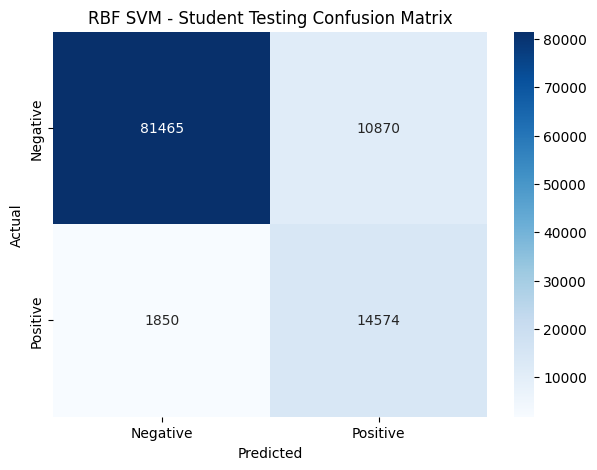

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, rbf_test_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RBF SVM - Student Testing Confusion Matrix")

plt.show()

Save RBF SVM

In [35]:

joblib.dump(
    rbf_svm,
    os.path.join(MODEL_DIR, "rbf_svm_baseline.pkl")
)

rbf_cv_df.to_csv(
    os.path.join(MODEL_DIR, "rbf_svm_cv_results.csv"),
    index=False
)

pd.DataFrame([rbf_test_results]).to_csv(
    os.path.join(MODEL_DIR, "rbf_svm_student_test_results.csv"),
    index=False
)

print("RBF SVM model and results saved successfully!")


RBF SVM model and results saved successfully!


Linear SVM vs RBF SVM

In [36]:

comparison = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "Accuracy": 0.8109397843,
        "Precision": 0.4367471721,
        "Recall": 0.8698246469,
        "Macro_F1": 0.7296990220
    },
    {
        "Model": "RBF SVM",
        "Accuracy": rbf_test_results["Accuracy"],
        "Precision": rbf_test_results["Precision"],
        "Recall": rbf_test_results["Recall"],
        "Macro_F1": rbf_test_results["Macro_F1"]
    }
])

display(comparison)


,Model,Accuracy,Precision,Recall,Macro_F1
0,Linear SVM,0.810940,0.436747,0.869825,0.729699
1,RBF SVM,0.883044,0.572787,0.887360,0.811886
